# Issue #5: Exploratory data analysis

Goal: understand the data before designing signals. The continuous series come from
`data.build_continuous` with the roll rule in `config.yaml` (5 trading days before expiry,
ratio-adjusted), so every return below is a same-contract return and rolls create no jumps.
The helper functions live in `src/eda.py`.

Sections: 1. data, 2. return distributions, 3. volatility, 4. correlations,
5. autocorrelation, 6. momentum persistence, 7. roll yield and term structure,
8. what this means for the strategy.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import eda
from src.config import load_config

cfg = load_config()
prices, continuous = eda.load_universe(cfg)
returns = eda.return_panel(continuous)
LOOKBACK = cfg["signal"]["lookback_days"]
VOL_WINDOW = cfg["signal"]["vol_lookback_days"]

# Categorical slots 1-4 of the reference palette, fixed per product.
COLORS = {"ES": "#2a78d6", "NQ": "#eb6834", "RTY": "#1baf7a", "YM": "#eda100"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "legend.frameon": False,
})
pd.options.display.float_format = "{:.4f}".format

## 1. The data

In [2]:
overview = pd.DataFrame({
    root: {
        "first date": cont.index.min().date(), "last date": cont.index.max().date(),
        "trade days": len(cont), "rolls": int(cont["roll"].sum()),
        "distinct expiries held": cont["expiry"].nunique(),
    } for root, cont in continuous.items()
}).T
overview

,first date,last date,trade days,rolls,distinct expiries held
ES,2010-06-07,2025-12-31,3920,63,64
NQ,2010-06-07,2025-12-31,3920,63,64
RTY,2017-07-10,2025-12-31,2136,34,35
YM,2010-06-07,2025-12-31,3923,63,64


In [3]:
gaps = eda.missing_days(continuous)
gaps.groupby("product")["date"].agg(["count", lambda d: ", ".join(x.strftime("%Y-%m-%d") for x in d)]).rename(
    columns={"count": "missing days", "<lambda_0>": "dates"})

,missing days,dates
product,,
ES,6,"2014-06-12, 2014-06-13, 2014-09-23, 2014-09-24..."
NQ,6,"2014-06-12, 2014-06-13, 2014-09-23, 2014-09-24..."
YM,3,"2014-10-03, 2020-02-27, 2020-06-30"


**Data quality.** ES and NQ have no rows on 2014-06-12 and 2014-06-13, 2014-09-23 to 2014-09-25 and
2014-12-31, and YM has none on 2014-10-03, 2020-02-27 and 2020-06-30. These are not exchange holidays (the other
products trade on those days), so they are gaps in the downloaded data. The return on the next available day then
spans the gap, which slightly overstates that day's move. Nine dates in 16 years is minor, but they should be
re-checked in #3's download (`data/README.md` reports no missing rows beyond holidays) before the final results.

ES, NQ and YM start in June 2010 (when Databento's CME data begins), RTY in July 2017. Any statistic
that mixes RTY with the others covers a shorter window, so cross-product comparisons below say which
window they use.

## 2. Return distributions

In [4]:
summary = eda.return_summary(returns)
summary.drop(columns="start")

,days,ann_return,ann_vol,skew,excess_kurtosis,min,max,pct_beyond_3sd,jarque_bera_p
ES,3919,0.1350,0.1713,-0.3244,12.0957,-0.1039,0.0980,0.0158,0.0000
NQ,3919,0.1823,0.2054,-0.1902,7.2431,-0.1089,0.1186,0.0148,0.0000
RTY,2135,0.0822,0.2436,-0.4812,8.6352,-0.1404,0.1013,0.0112,0.0000
YM,3922,0.1193,0.1635,-0.3836,16.9893,-0.1129,0.1141,0.0143,0.0000


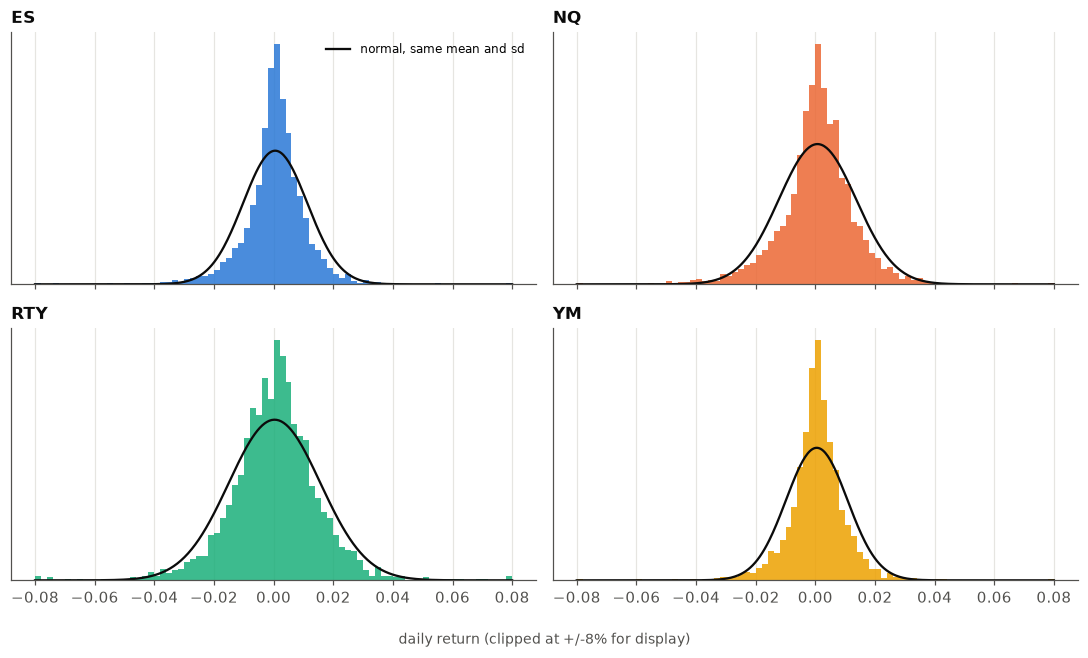

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
bins = np.linspace(-0.08, 0.08, 81)
for ax, (root, ret) in zip(axes.flat, returns.items()):
    ret = ret.dropna()
    ax.hist(ret.clip(-0.08, 0.08), bins=bins, density=True, color=COLORS[root], alpha=0.85)
    grid = np.linspace(-0.08, 0.08, 400)
    normal = np.exp(-0.5 * ((grid - ret.mean()) / ret.std()) ** 2) / (ret.std() * np.sqrt(2 * np.pi))
    ax.plot(grid, normal, color=INK, lw=1.5, label="normal, same mean and sd")
    ax.set_title(root, loc="left")
    ax.set_yticks([])
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.supxlabel("daily return (clipped at +/-8% for display)", color=MUTED, fontsize=9)
fig.tight_layout()
plt.show()

**Findings.**
- Returns are far from normal. Excess kurtosis is about 7 to 17, and Jarque-Bera rejects normality for
  every product. Around 1.1% to 1.6% of days are more than 3 standard deviations from the mean, against
  0.27% for a normal distribution.
- Skew is negative for all four (about -0.2 to -0.5): the big days are more often down.
- Annualised volatility is about 16% (YM) to 24% (RTY) over the full sample, so volatility targeting
  will scale the products quite differently.
- Sizing and risk limits should assume fat tails. Position sizes based on a normal 1-day 99% loss would
  understate the risk.

## 3. Volatility over time

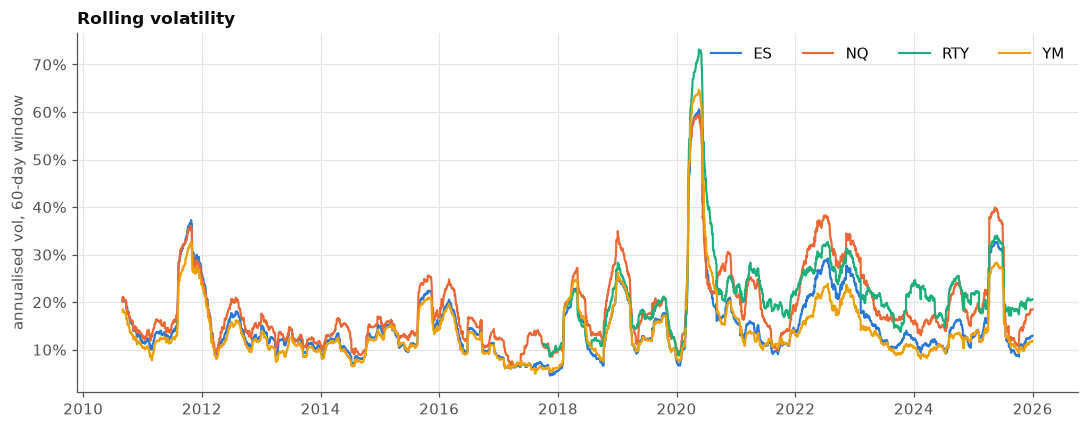

,median,mean,max,date of max
ES,0.1291,0.1524,0.6056,2020-05-18
NQ,0.1628,0.1884,0.5943,2020-05-18
RTY,0.2086,0.2251,0.7315,2020-05-18
YM,0.1210,0.1435,0.6469,2020-05-19


In [6]:
vol = eda.rolling_vol(returns, VOL_WINDOW)
fig, ax = plt.subplots(figsize=(10, 4))
for root in vol:
    ax.plot(vol.index, vol[root], color=COLORS[root], lw=1.4, label=root)
ax.set_ylabel(f"annualised vol, {VOL_WINDOW}-day window")
ax.set_title("Rolling volatility", loc="left")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(ncol=4, loc="upper right")
fig.tight_layout()
plt.show()

pd.DataFrame({"median": vol.median(), "mean": vol.mean(), "max": vol.max(), "date of max": vol.idxmax().dt.date})

**Findings.**
- Volatility clusters: calm stretches of roughly 10% to 15% are interrupted by spikes (2010-11, 2015, 2018-19,
  2022, 2025, and above all March 2020, when the 60-day measure peaked at about 60% to 73%).
- The 60-day measure peaks in May 2020 only because the window lags the March crash. A volatility target
  based on it reacts slowly on the way up, so the strategy takes the March 2020 shock at nearly full size.
  A shorter window, or an EWMA, is worth testing in #10.
- The median volatility is below the mean (for ES about 13% against 15%), so the average level overstates a typical day.

## 4. Correlations across contracts

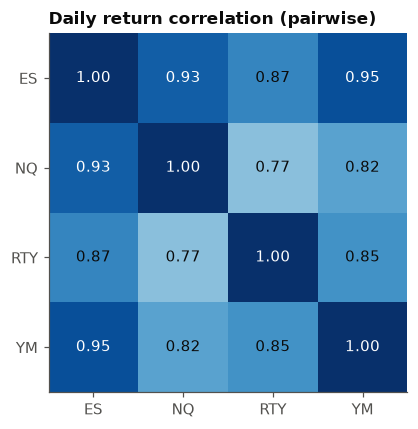

Same window for all four (from RTY's first date):


,ES,NQ,RTY,YM
ES,1.0000,0.9300,0.8700,0.9400
NQ,0.9300,1.0000,0.7700,0.8000
RTY,0.8700,0.7700,1.0000,0.8500
YM,0.9400,0.8000,0.8500,1.0000


In [7]:
corr = returns.corr()
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(corr.values, cmap="Blues", vmin=0.6, vmax=1.0)
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.88 else INK)
ax.set_title("Daily return correlation (pairwise)", loc="left")
fig.tight_layout()
plt.show()

since_rty = returns.loc[returns["RTY"].first_valid_index():].corr()
print("Same window for all four (from RTY's first date):")
since_rty.round(2)

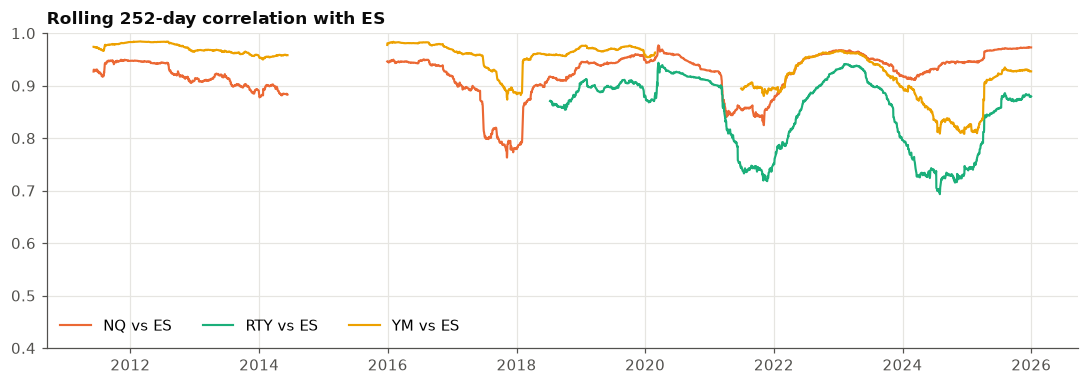

In [8]:
window = 252
rolling = {f"{b} vs ES": returns["ES"].rolling(window).corr(returns[b]) for b in ["NQ", "RTY", "YM"]}
fig, ax = plt.subplots(figsize=(10, 3.6))
for name, series in rolling.items():
    ax.plot(series.index, series, color=COLORS[name.split()[0]], lw=1.4, label=name)
ax.set_ylim(0.4, 1.0)
ax.set_title(f"Rolling {window}-day correlation with ES", loc="left")
ax.legend(ncol=3, loc="lower left")
fig.tight_layout()
plt.show()

**Findings.**
- The four products are close to one factor. ES-YM is about 0.95, ES-NQ about 0.93, and even the least
  related pair (NQ-RTY) is about 0.77.
- The 252-day rolling correlation with ES stays between roughly 0.7 and 0.98, so it is high in every
  period but not constant. Trading all four is not four independent bets, so the vol-targeted portfolio should limit gross
  leverage across products and not only per product.
- The sample window does not change the picture (the same-window matrix matches the full-sample one).

## 5. Autocorrelation

In [9]:
lags = [1, 2, 3, 4, 5, 10, 21]
acf = eda.autocorrelation(returns, lags)
band = eda.autocorrelation_band(len(returns["ES"].dropna()))
print(f"approximate 95% band for white noise (ES sample size): +/-{band:.3f}")
acf

approximate 95% band for white noise (ES sample size): +/-0.031


,ES,NQ,RTY,YM
lag,,,,
1,-0.0901,-0.0781,-0.0830,-0.0888
2,0.0520,0.0238,0.0789,0.0803
3,-0.0325,-0.0324,-0.0111,-0.0366
4,-0.0508,-0.0344,-0.0572,-0.0533
5,-0.0089,-0.0050,0.0501,0.0087
10,-0.0137,-0.0153,-0.0091,-0.0566
21,0.0178,0.0217,0.0263,-0.0121


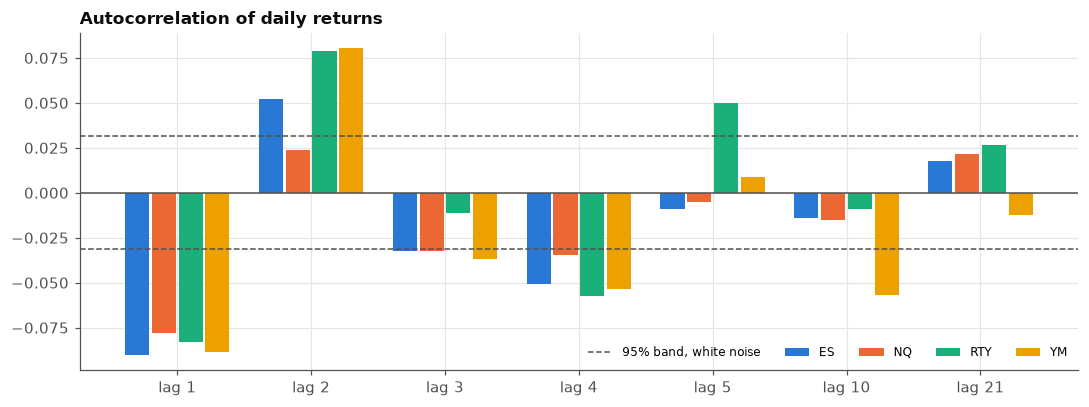

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.2
x = np.arange(len(lags))
for k, root in enumerate(acf.columns):
    ax.bar(x + (k - 1.5) * width, acf[root], width=width * 0.9, color=COLORS[root], label=root)
ax.axhline(band, color=MUTED, lw=1, ls="--")
ax.axhline(-band, color=MUTED, lw=1, ls="--", label="95% band, white noise")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x, [f"lag {l}" for l in lags])
ax.set_title("Autocorrelation of daily returns", loc="left")
ax.legend(ncol=5, loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

**Findings.**
- Lag-1 autocorrelation is negative for all four (about -0.08 to -0.09), well outside the white-noise
  band. Daily returns show a small amount of reversal, not momentum.
- Beyond lag 1 most values are inside or close to the band. Lag 2 is mildly positive, and a few
  individual values (for example YM at lag 10) fall slightly outside it.
- Daily autocorrelation says little about momentum over months, which is what the strategy uses
  (next section). It does mean the signal should use returns measured over weeks to months and should
  skip very recent days, or a day-to-day flip in the sign will add turnover without adding return.

## 6. Momentum persistence

In [11]:
horizons = [21, 63]
persistence = {h: eda.momentum_persistence(returns, LOOKBACK, h) for h in horizons}
for h, table in persistence.items():
    print(f"Signal: sign of trailing {LOOKBACK}-day return; forward horizon {h} days, non-overlapping periods")
    display(table)

Signal: sign of trailing 252-day return; forward horizon 21 days, non-overlapping periods


,periods,pct_long,mean_fwd_after_up,mean_fwd_after_down,mean_fwd_all,strategy_mean,t_stat,hit_rate
ES,174.0000,0.8621,0.0088,0.0207,0.0104,0.0047,1.4971,0.6494
NQ,174.0000,0.9080,0.0134,0.0253,0.0145,0.0098,2.5258,0.6437
RTY,89.0000,0.5169,-0.0001,0.0110,0.0053,-0.0053,-0.8077,0.5169
YM,174.0000,0.8678,0.0055,0.0322,0.0091,0.0006,0.1669,0.5747


Signal: sign of trailing 252-day return; forward horizon 63 days, non-overlapping periods


,periods,pct_long,mean_fwd_after_up,mean_fwd_after_down,mean_fwd_all,strategy_mean,t_stat,hit_rate
ES,58.0000,0.8448,0.0279,0.0465,0.0308,0.0163,1.9263,0.7069
NQ,58.0000,0.9138,0.0440,0.0345,0.0431,0.0372,3.4699,0.7586
RTY,29.0000,0.5862,-0.0192,0.0645,0.0154,-0.0380,-1.7417,0.3448
YM,58.0000,0.8966,0.0253,0.0314,0.0259,0.0194,2.7251,0.6897


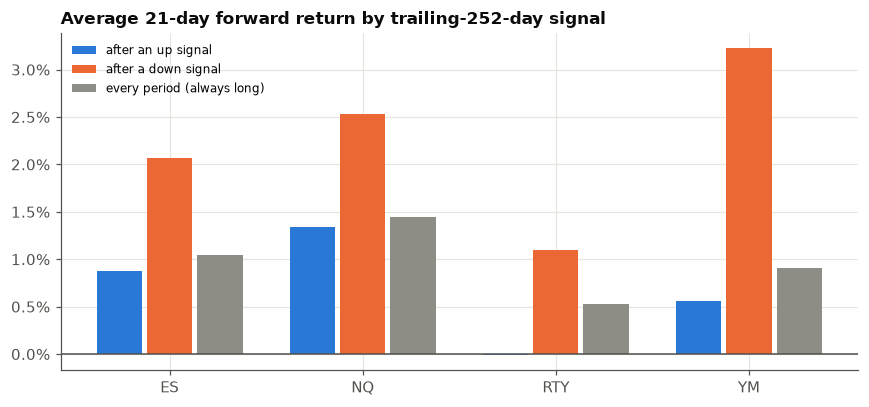

In [12]:
h = 21
table = persistence[h]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(table))
width = 0.26
for k, (col, label, color) in enumerate([
    ("mean_fwd_after_up", "after an up signal", "#2a78d6"),
    ("mean_fwd_after_down", "after a down signal", "#eb6834"),
    ("mean_fwd_all", "every period (always long)", "#8d8c85"),
]):
    ax.bar(x + (k - 1) * width, table[col], width=width * 0.9, color=color, label=label)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x, table.index)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
ax.set_title(f"Average {h}-day forward return by trailing-{LOOKBACK}-day signal", loc="left")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

**Findings.** This is in-sample description, not a backtest: no costs, no sizing, and the horizon
choice and the lookback are the config defaults, not tuned.
- The signal is long most of the time for ES, NQ and YM (about 86% to 91% of periods), because these
  indices trended up over 2010 to 2025. For RTY it is long only about half the time (2017 onward).
- Following the signal did **not** beat always being long for ES, NQ or YM. For each of them the
  average forward return after an up signal is no higher than the all-periods average, and after a
  down signal it is higher (the short legs lost money; the market usually rebounded). The
  signal-times-forward return is positive for ES, NQ and YM, but only because the long periods
  earn the market drift. RTY shows the same pattern but with a negative signal-times-forward return.
- The t-statistics are modest at 21 days (about -0.8 to 2.5) and larger at 63 days for NQ and YM,
  but those windows have only 58 to 174 non-overlapping periods, so they are weak evidence either way.
- So the case for time-series momentum here rests on risk management (exiting before long drawdowns
  and scaling by volatility) and not on a higher average return than buy-and-hold. The benchmark in
  the plan (a volatility-matched buy-and-hold) is the right comparison. Judging it needs the
  backtest in #7 to #9.

## 7. Roll yield and term structure

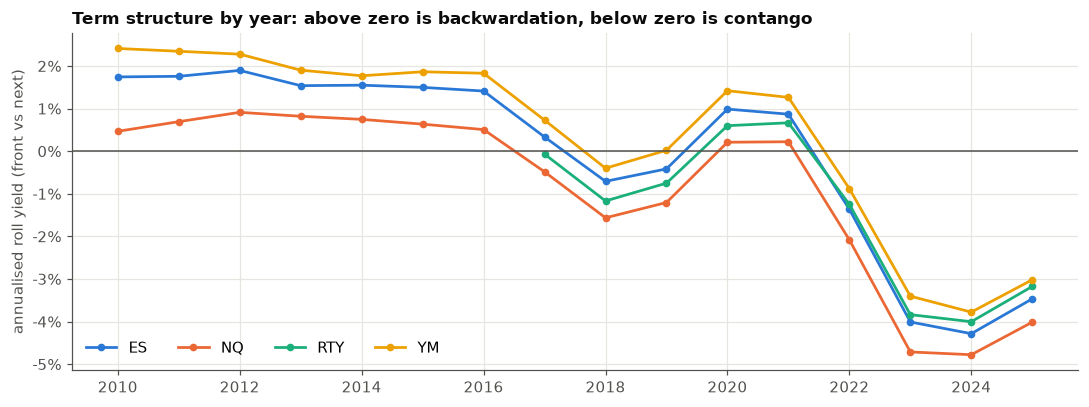

In [13]:
term = {root: eda.term_structure(prices[root], continuous[root]) for root in continuous}
yearly = pd.DataFrame({root: t["roll_yield"].groupby(t.index.year).mean() for root, t in term.items()})
fig, ax = plt.subplots(figsize=(10, 3.8))
for root in yearly:
    ax.plot(yearly.index, yearly[root], color=COLORS[root], lw=1.8, marker="o", ms=4, label=root)
ax.axhline(0, color=MUTED, lw=1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("annualised roll yield (front vs next)")
ax.set_title("Term structure by year: above zero is backwardation, below zero is contango", loc="left")
ax.legend(ncol=4, loc="lower left")
fig.tight_layout()
plt.show()

In [14]:
rolls = pd.DataFrame({root: eda.roll_summary(cont) for root, cont in continuous.items()}).T
rolls

,rolls,mean_gap,pct_contango,rolls_per_year,per_year
ES,63.0000,0.0002,0.3810,4.0469,0.0009
NQ,63.0000,0.0023,0.4603,4.0469,0.0095
RTY,34.0000,0.0038,0.6765,4.0111,0.0153
YM,63.0000,-0.0008,0.3333,4.0469,-0.0032


**Findings.**
- Equity index futures price off financing cost minus dividend yield. The curve was in **backwardation**
  (positive roll yield, about +0.5% to +2.4% a year depending on the product) through 2010 to 2016, when rates were near zero, flipped
  to **contango** around 2018 and again from 2022, and reached about -3% to -5% a year (ES, NQ, RTY, YM)
  in 2023 to 2025 as rates rose.
- Over the whole sample the average roll gap is small (a fraction of a percent per roll, between about
  -0.3% and +1.5% a year of drag depending on the product, highest for RTY). It is not stable over time,
  though: a long position paid noticeably more to roll in 2023 to 2025 than in the early 2010s.
- Rolling with the next contract at its own settle (as `build_continuous` does) keeps the returns
  honest. An unadjusted series would show 4 artificial jumps a year equal to this gap.
- The strategy's short legs earn the roll in contango and pay it in backwardation, the reverse of the
  long legs. The cost model in #7 should charge each roll's real bid-ask cost on top of this effect.

## 8. What this means for the strategy

1. **Fat tails and negative skew.** Size and set loss limits for tails, not for a normal distribution.
2. **Volatility clusters, and the 60-day estimate lags.** Test a shorter or exponentially weighted
   window in the robustness work (#10).
3. **One dominant factor across the four products.** Vol targeting per product is not enough; the
   leverage and margin limit has to apply to the portfolio.
4. **Lag-1 reversal at about -0.08 to -0.09.** Daily sign flips will add turnover without edge.
   Consider a minimum holding period or a signal band.
5. **Trend persistence is weak in-sample, and the signal is mostly long.** Expect the strategy to
   behave like a lower-risk version of buy-and-hold with some drawdown protection, and compare it
   with the volatility-matched benchmark rather than raw buy-and-hold.
6. **Roll cost depends on the rate regime.** Report results by sub-period (pre-2018, 2018 to 2021,
   2022 onward) so the recent contango is visible.

Limits of this analysis: it uses daily settles only, it stops at the data's last date (2025-12-31), RTY
has under half the history of the others, and nothing here is out-of-sample.